In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 02 · EDA — qué hay realmente en los datos de Confiar

El EDA no es "hacer gráficos": es **descubrir qué decisiones hay que tomar antes de modelar**. Cada hallazgo de este
notebook termina en una decisión escrita (tabla final, sección 7), y cada decisión se convierte en código con pruebas
en `src/proyecto/data/` (notebook 03).

Vamos **de lo macro a lo micro**: qué es una fila y cómo se construyó el dataset → el objetivo → la calidad de los
datos → qué cambia con el tiempo → qué variables separan a quien radica → qué suena a fuga.

Preguntas guía del curso: (1) unidad de análisis · (2) objetivo · (3) suciedad · (4) qué debería ser estable ·
(5) sospecha de fuga.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

from proyecto.config import BASE_FEATURES, LEAKAGE_SUSPECTS, MIN_WAGE_BY_YEAR, RAW_FILE, TARGET
from proyecto.data.cleaning import add_product_flags, add_time_context, drop_personal_data
from proyecto.viz import (ALERT, CHURN, LIGHT, NEUTRAL, STAY, SUBTEXT, TEXT, fmt_num, fmt_pct, note, pct_axis,
                          rate_by_quantile, set_style, table, thousands_axis, titled)

set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

raw_full = pd.read_excel(RAW_FILE)
n_rows, n_nit = len(raw_full), raw_full["Nit"].nunique()   # solo se cuenta; el Nit nunca se muestra
raw = drop_personal_data(raw_full)                          # elimina el Nit y agrega associate_id
del raw_full
df = add_time_context(raw)                                  # año de proceso y grupo (solo para analizar)
print(f"{fmt_num(df.shape[0])} filas x {raw.shape[1] - 1} columnas originales (sin el Nit)")

194.073 filas x 24 columnas originales (sin el Nit)


## 1. ¿Qué es una fila? ¿Cómo se construyó el dataset?

In [3]:
process = pd.PeriodIndex(df["anio_mes_proceso"], freq="M")
cohort = pd.PeriodIndex(df["cohorte"], freq="M")
months_between = (process.year * 12 + process.month) - (cohort.year * 12 + cohort.month)

print(f"Filas: {fmt_num(n_rows)} · documentos (Nit) distintos: {fmt_num(n_nit)} -> una fila por asociado: {n_rows == n_nit}")
print(f"Mes de vinculación (cohorte): de {cohort.min()} a {cohort.max()} ({cohort.nunique()} meses)")
print(f"Mes del registro (proceso):    de {process.min()} a {process.max()} ({process.nunique()} meses)")
print(f"antig_meses = meses entre cohorte y proceso en el {fmt_pct((months_between == df['antig_meses']).mean())} de las filas")

Filas: 194.073 · documentos (Nit) distintos: 194.073 -> una fila por asociado: True
Mes de vinculación (cohorte): de 2017-01 a 2025-12 (108 meses)
Mes del registro (proceso):    de 2017-01 a 2025-12 (108 meses)
antig_meses = meses entre cohorte y proceso en el 100,0 % de las filas


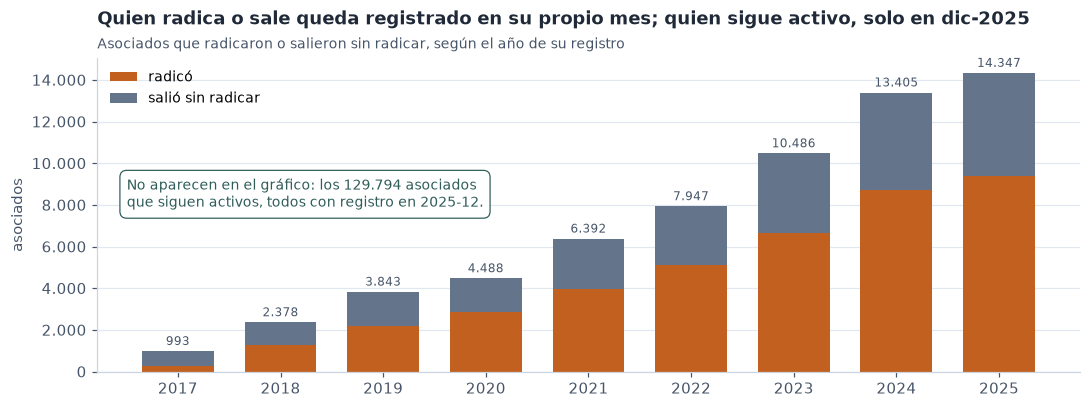

In [4]:
labels = {"activo": "sigue activo", "salio_sin_radicar": "salió sin radicar", "radica": "radicó"}
colors = {"activo": STAY, "salio_sin_radicar": NEUTRAL, "radica": CHURN}
counts = pd.crosstab(df["process_year"], df["stratum"])[list(labels)]

active_last = counts.loc[2025, "activo"]
active_months = df.loc[df["stratum"] == "activo", "anio_mes_proceso"].unique()

fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(counts))
for key in ["radica", "salio_sin_radicar"]:
    bars = ax.bar(counts.index.astype(str), counts[key], bottom=bottom, color=colors[key], label=labels[key], width=0.7)
    bottom += counts[key].to_numpy()
ax.bar_label(bars, labels=[fmt_num(v) for v in bottom], fontsize=8, color=SUBTEXT, padding=2)
ax.set_ylabel("asociados")
thousands_axis(ax)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.text(0.03, 0.62, f"No aparecen en el gráfico: los {fmt_num(active_last)} asociados\nque siguen activos, "
        f"todos con registro en {', '.join(active_months)}.", transform=ax.transAxes, fontsize=9, color=STAY,
        va="top", bbox={"boxstyle": "round,pad=0.5", "fc": "white", "ec": STAY, "lw": 0.8})
titled(ax, "Quien radica o sale queda registrado en su propio mes; quien sigue activo, solo en dic-2025",
       "Asociados que radicaron o salieron sin radicar, según el año de su registro")
plt.tight_layout(); plt.show()

**Hallazgos.**

- **Una fila es un asociado**: hay tantos Nit distintos como filas. Ningún asociado se repite, así que partir por
  asociado y partir por fila es lo mismo (igual se parte por asociado, con una prueba, en el notebook 03).
- **Cada asociado está "fotografiado" en un mes distinto.** Según el README del equipo, quien radica se registra en el
  mes en que radicó, y quien no radica, en el último mes en que se le vio. El gráfico lo confirma: todos los activos
  están en diciembre de 2025, mientras que quien radicó o salió está repartido entre 2017 y 2025.
- `antig_meses` es exactamente la distancia entre la cohorte y el mes del registro en todas las filas.

> **Consecuencia.** El **mes del registro dice casi solo la respuesta**: si no es diciembre de 2025, el asociado
> radicó o salió. Y como `cohorte + antig_meses` lo reconstruye exactamente, las **dos fechas** son una fuga
> (se mide en la sección 6 y se demuestra en el notebook 03).

## 2. El objetivo

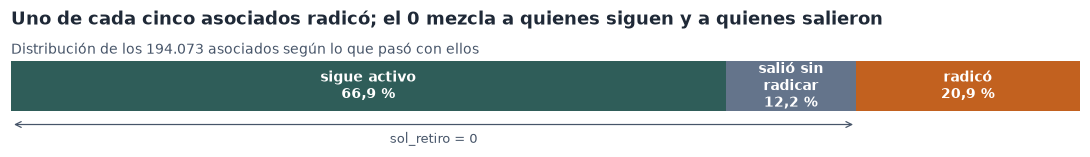

Tasa de radicación (sol_retiro = 1): 20,92 % · vacíos en el objetivo: 0
Línea base: responder siempre 'no radica' acierta el 79,1 % y no encuentra a nadie.
Asociados por grupo: {'sigue activo': '129.794', 'salió sin radicar': '23.688', 'radicó': '40.591'}


In [5]:
share = df["stratum"].value_counts(normalize=True)[list(labels)]
fig, ax = plt.subplots(figsize=(10, 2.1))
left = 0
for key in labels:
    ax.barh(0, share[key], left=left, color=colors[key], height=0.55)
    ax.text(left + share[key] / 2, 0, f"{labels[key].replace('sin ', 'sin' + chr(10))}\n{fmt_pct(share[key])}",
            ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += share[key]
ax.set_xlim(0, 1); ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
ax.annotate("", xy=(0, -0.42), xytext=(share["activo"] + share["salio_sin_radicar"], -0.42),
            arrowprops={"arrowstyle": "<->", "color": SUBTEXT, "lw": 0.8}, annotation_clip=False)
ax.text((share["activo"] + share["salio_sin_radicar"]) / 2, -0.62, "sol_retiro = 0", ha="center", color=SUBTEXT,
        fontsize=8.5)
titled(ax, f"Uno de cada cinco asociados radicó; el 0 mezcla a quienes siguen y a quienes salieron",
       "Distribución de los 194.073 asociados según lo que pasó con ellos")
plt.tight_layout(); plt.show()

rate = df[TARGET].mean()
print(f"Tasa de radicación (sol_retiro = 1): {fmt_pct(rate, 2)} · vacíos en el objetivo: {df[TARGET].isna().sum()}")
print(f"Línea base: responder siempre 'no radica' acierta el {fmt_pct(1 - rate, 1)} y no encuentra a nadie.")
print("Asociados por grupo:", {labels[k]: fmt_num(v) for k, v in df["stratum"].value_counts()[list(labels)].items()})

**Hallazgo.** Uno de cada cinco asociados radicó: desbalance moderado. Predecir siempre "no radica" acierta casi el
80 % y no sirve para nada: por eso **la exactitud no es la métrica** (notebook 01, sección 6).

El hallazgo que no esperábamos es que **el 0 no es un grupo homogéneo**. Además de los activos hay un 12 % de
asociados que **dejó de aparecer sin radicar**. El README del equipo describe retiros que no son voluntarios (cruce de
cuentas o de cartera, incorrección, herederos de fallecidos); es probable que sean ellos, pero **hay que confirmarlo
con la fuente**. ¿Se parecen más a quien sigue o a quien radica?

In [6]:
profile = df.groupby("stratum").agg(
    asociados=(TARGET, "size"),
    antiguedad_mediana=("antig_meses", "median"),
    aportes_mediana=("saldo_aportes", "median"),
    sin_aportes=("saldo_aportes", lambda s: (s == 0).mean()),
    nunca_capitalizo=("porc_meses_capitaliza_aportes", lambda s: (s == 0).mean()),
    trx_mediana=("prom_trx", "median"),
).reindex(list(labels))
profile.index = [labels[k] for k in profile.index]
display(table(profile, decimals=2, pct_cols=["sin_aportes", "nunca_capitalizo"]))

,asociados,antiguedad_mediana,aportes_mediana,sin_aportes,nunca_capitalizo,trx_mediana
sigue activo,129.794,"42,00","0,60","1,0 %","0,7 %","1,40"
salió sin radicar,23.688,"17,00","0,27","32,4 %","31,3 %","1,31"
radicó,40.591,"27,00","0,61","0,1 %","0,1 %","1,65"


**Lectura.** Quien sale sin radicar es un perfil propio: menos antigüedad, la mitad de los aportes y, sobre todo, un
tercio **sin aportes** al momento de su último registro (frente a casi nadie en los otros dos grupos). No es "un activo
más": es alguien cuya relación ya se había vaciado.

**Decisión:** se conservan con `sol_retiro = 0` (no radicaron, y así los trató el equipo), pero se marcan en una
columna auxiliar `exit_without_request` que **no entra al modelo**. En la etapa 4 se mide el modelo con y sin ellos.

## 3. ¿Qué tan sucios están los datos?

In [7]:
features = df[BASE_FEATURES]
print("Tipos de dato:", features.dtypes.astype(str).value_counts().to_dict())
print("Vacíos en las 21 variables:", int(features.isna().sum().sum()))

dup_mask = df[BASE_FEATURES + [TARGET]].duplicated(keep=False)
extra = df[BASE_FEATURES + [TARGET]].duplicated().sum()
print(f"Filas con un gemelo exacto (sin contar el Nit): {fmt_num(dup_mask.sum())} filas, {fmt_num(extra)} copias de más")
print(f"   ¿todas son de asociados distintos? {df.loc[dup_mask, 'associate_id'].is_unique} · "
      f"radican: {int(df.loc[dup_mask, TARGET].sum())} · aportes promedio: {fmt_num(df.loc[dup_mask, 'saldo_aportes'].mean(), 3)}")

Tipos de dato: {'float64': 15, 'int64': 6}
Vacíos en las 21 variables: 0


Filas con un gemelo exacto (sin contar el Nit): 306 filas, 163 copias de más
   ¿todas son de asociados distintos? True · radican: 0 · aportes promedio: 0,002


**Hallazgos.**

- Las 21 variables son numéricas y **no hay vacíos**: el equipo ya trató nulos y atípicos en el origen. Por eso los
  problemas aquí no son de formato, sino de **significado** (lo que sigue).
- Hay filas idénticas, pero **cada una es un asociado distinto** (Nit distinto), ninguno radica y casi no tienen aportes:
  son asociados recién vinculados sin movimiento. El notebook del equipo las eliminaba; aquí **se conservan**, porque
  son personas reales y el modelo verá ese perfil en producción. Al no repetirse ningún asociado, no hay fuga.

### Valores extremos e imposibles

Miramos dónde **se disparan los percentiles** y cuántas filas quedan pegadas al máximo.

In [8]:
continuous = [c for c in BASE_FEATURES if df[c].nunique() > 2]
q = df[continuous].quantile([0.5, 0.9, 0.95, 0.99, 0.999, 1.0]).T
q.columns = ["mediana", "p90", "p95", "p99", "p99,9", "máximo"]
q["filas en el máximo"] = [int((df[c] == df[c].max()).sum()) for c in continuous]
q["mínimo"] = df[continuous].min()
display(table(q[["mínimo", "mediana", "p90", "p95", "p99", "p99,9", "máximo", "filas en el máximo"]], decimals=2))

,mínimo,mediana,p90,p95,p99,"p99,9",máximo,filas en el máximo
saldo_aportes,"0,00","0,54","3,14","4,75","8,70","12,69","52,88",1
prom_saldo_capitalizacion_aportes,"-11,88","0,02","0,10","0,18","0,67","3,18","11,39",1
porc_meses_capitaliza_aportes,"0,00","0,25","0,90","0,96","1,00","1,00","1,00",6.194
antig_meses,"0,00","35,00","85,00","95,00","105,00","107,00","107,00",850
saldo_ahorro_prog,"0,00","0,00","0,71","3,63","21,42","30,00","30,00",1.260
prom_saldo_ahorro_prog,"0,00","0,00","2,03","4,78","19,69","27,90","27,90",1.165
rel_min-max_ahorro_prog,"0,00","0,00","0,16","0,88","1,00","1,00","1,00",2.700
saldo_cta,"0,00","0,00","0,02","0,35","5,63","30,46","35,00",161
prom_saldo_cta,"0,00","0,00","0,40","1,04","5,33","10,00","10,00",831
rel_min-max_saldo_cta,"0,00","0,00","0,00","0,42","1,00","1,00","1,00",6.803


**Hallazgos.**

- **Topes puestos en el origen.** Cinco variables tienen cientos de filas con exactamente el mismo máximo
  (`saldo_ahorro_prog` = 30, `prom_saldo_ahorro_prog` = 27,9, `prom_saldo_cta` = 10, `ingresos` = 22,
  `saldo_cta` = 35). Es la huella del tratamiento de atípicos que hizo el equipo: **no se vuelven a recortar**.
- **Colas largas reales.** `prom_saldo_cartera` va de un p99,9 cercano a 114 a un máximo de 1.333, y `prom_trx` de 78 a
  531. No hay salto de corrupción como en CreditSight: son pocos asociados con mucho crédito o mucha actividad.
  **Decisión:** no se recortan; en la etapa 4 se aplica una transformación logarítmica **dentro del Pipeline** para los
  modelos sensibles a la escala (lineales, vecinos). Los árboles no la necesitan.
- **Edad** con valores que una persona asociada no puede tener (abajo) y **capitalización negativa** (más abajo).

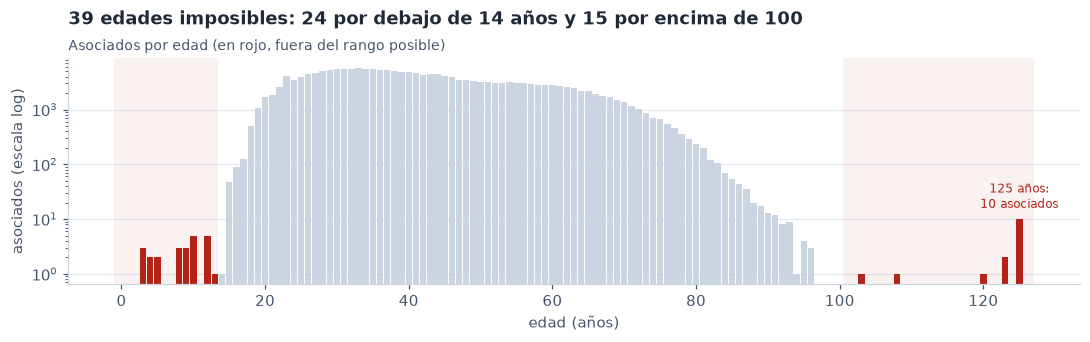

Edades de 3 a 13 años: 24 · de 101 a 125: 15 · de 15 a 17 años: 263


In [9]:
age = df["edad"]
too_low, too_high = (age < 14).sum(), (age > 100).sum()
counts_age = age.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(counts_age.index, counts_age.values, color=[ALERT if (a < 14 or a > 100) else LIGHT for a in counts_age.index],
       width=0.9)
ax.set_yscale("log")
ax.set_xlabel("edad (años)"); ax.set_ylabel("asociados (escala log)")
ax.axvspan(-1, 13.5, color=ALERT, alpha=0.06, lw=0); ax.axvspan(100.5, 127, color=ALERT, alpha=0.06, lw=0)
ax.text(125, counts_age.get(125, 1) * 1.6, f"125 años:\n{counts_age.get(125, 0)} asociados", ha="center", fontsize=8,
        color=ALERT)
ax.grid(axis="x", visible=False)
titled(ax, f"{too_low + too_high} edades imposibles: {too_low} por debajo de 14 años y {too_high} por encima de 100",
       "Asociados por edad (en rojo, fuera del rango posible)")
plt.tight_layout(); plt.show()
print(f"Edades de 3 a 13 años: {too_low} · de 101 a 125: {too_high} · de 15 a 17 años: {int(age.between(15, 17).sum())}")

**Hallazgo.** Por debajo de 14 años hay entre 1 y 5 asociados por edad, y en los 15 años el conteo salta a decenas: los
de abajo son errores de digitación, no un grupo real. Por encima de 100, diez asociados tienen **exactamente 125 años**:
un valor de relleno (centinela). Entre 15 y 17 años hay asociados reales (menores vinculados), que se conservan.

**Decisión:** edad fuera de **14–100 años → vacío**, sin borrar la fila. El vacío se imputa con la mediana **dentro
del Pipeline** (etapa 4), aprendida solo con entrenamiento.

In [10]:
neg = df["prom_saldo_capitalizacion_aportes"] < 0
print(f"Capitalización promedio negativa: {fmt_num(neg.sum())} asociados ({fmt_pct(neg.mean(), 2)})")
print("   por grupo:", {labels[k]: int(v) for k, v in df.loc[neg, "stratum"].value_counts().items()})
print(f"   mediana: {fmt_num(df.loc[neg, 'prom_saldo_capitalizacion_aportes'].median(), 4)} · "
      f"mínimo: {fmt_num(df.loc[neg, 'prom_saldo_capitalizacion_aportes'].min(), 2)}")

Capitalización promedio negativa: 421 asociados (0,22 %)
   por grupo: {'sigue activo': 318, 'salió sin radicar': 78, 'radicó': 25}
   mediana: -0,0000 · mínimo: -11,88


**Hallazgo y decisión.** Una capitalización promedio negativa significa que el saldo de aportes **bajó** durante la
vinculación: es posible con un **retiro parcial** de aportes, que el README del equipo menciona como otra forma de
ruptura. La mayoría están entre los activos y casi todos los valores son muy cercanos a cero. **Se conservan:** no es
un error, es una señal (y son el 0,22 % de las filas).

### Ceros que significan "no tiene el producto"

In [11]:
flags = add_product_flags(df)
products = {"has_loan": "crédito (cartera)", "has_prog_savings": "ahorro programado / CDT", "has_account": "cuenta de ahorro"}
rows = []
for flag, label in products.items():
    rows.append({"producto": label, "sin el producto": 1 - flags[flag].mean(),
                 "tasa de radicación sin él": flags.loc[flags[flag] == 0, TARGET].mean(),
                 "tasa de radicación con él": flags.loc[flags[flag] == 1, TARGET].mean()})
products_table = pd.DataFrame(rows).set_index("producto")
display(table(products_table, pct_cols=list(products_table.columns)))
loans = flags["has_loan"] == 1
print(f"rel_min-max_saldo_cartera = 0: {fmt_pct((flags['rel_min-max_saldo_cartera'] == 0).mean())} de todos los asociados; "
      f"de ellos, {fmt_pct((~loans & (flags['rel_min-max_saldo_cartera'] == 0)).sum() / (flags['rel_min-max_saldo_cartera'] == 0).sum())} nunca tuvo crédito")

,sin el producto,tasa de radicación sin él,tasa de radicación con él
producto,,,
crédito (cartera),"51,8 %","21,8 %","20,0 %"
ahorro programado / CDT,"49,9 %","19,4 %","22,5 %"
cuenta de ahorro,"42,5 %","22,0 %","20,1 %"


rel_min-max_saldo_cartera = 0: 86,5 % de todos los asociados; de ellos, 59,9 % nunca tuvo crédito


**Hallazgos.**

- Entre el 42 % y el 52 % de los asociados **no tiene** cada producto: su saldo promedio es cero. No son vacíos ni
  errores: **no se imputan**.
- Tener o no cada producto, por sí solo, mueve poco la tasa de radicación (menos de 3,5 puntos de diferencia).
- **Las razones mínimo/máximo son ambiguas en cero:** `rel_min-max_saldo_cartera = 0` puede ser "nunca tuvo crédito" o
  "tuvo crédito y en algún mes llegó a cero". La mayoría de esos ceros son lo primero (cifra arriba).

**Decisión:** se agregan tres indicadores `has_loan`, `has_prog_savings` y `has_account` (1 si el promedio del saldo es
mayor que cero), para que el modelo distinga "no tiene" de "tiene poco".

## 4. ¿Qué debería ser estable y no lo es?

Cada asociado aparece una sola vez, así que no se puede revisar si su edad o su ingreso cambian de un mes a otro. La
pregunta se traslada al **tiempo**: ¿hay variables cuyo valor depende del **año del registro** y no del asociado?
El ingreso es el candidato natural.

In [12]:
wage_rows = []
for year, wage in MIN_WAGE_BY_YEAR.items():
    hit = np.isclose(df["ingresos"], wage, rtol=0, atol=1e-6)
    wage_rows.append({"año": year, "salario mínimo (millones)": wage, "asociados con ese ingreso exacto": int(hit.sum()),
                      "% registrados ese mismo año": (df.loc[hit, "process_year"] == year).mean(),
                      "tasa de radicación": df.loc[hit, TARGET].mean()})
wages = pd.DataFrame(wage_rows).set_index("año")
any_wage = sum(r["asociados con ese ingreso exacto"] for r in wage_rows)
display(table(wages, decimals=4, pct_cols=["% registrados ese mismo año", "tasa de radicación"]))
print(f"Asociados cuyo ingreso es exactamente un salario mínimo de 2017–2025: {fmt_num(any_wage)} ({fmt_pct(any_wage / len(df))})")
print(f"Tasa de radicación de todos los demás: {fmt_pct(df.loc[~np.isclose(df['ingresos'].to_numpy()[:, None], np.array(list(MIN_WAGE_BY_YEAR.values()))[None, :], rtol=0, atol=1e-6).any(1), TARGET].mean())}")

,salario mínimo (millones),asociados con ese ingreso exacto,% registrados ese mismo año,tasa de radicación
año,,,,
2017,"0,7377",790,"32,4 %","27,5 %"
2018,"0,7812",993,"25,3 %","31,3 %"
2019,"0,8281",1.512,"24,1 %","34,8 %"
2020,"0,8778",1.292,"24,8 %","35,0 %"
2021,"0,9085",1.993,"24,2 %","34,2 %"
2022,"1,0000",7.195,"16,2 %","29,3 %"
2023,"1,1600",5.005,"21,5 %","26,6 %"
2024,"1,3000",9.112,"16,4 %","21,0 %"
2025,"1,4235",16.714,"100,0 %","5,2 %"


Asociados cuyo ingreso es exactamente un salario mínimo de 2017–2025: 44.606 (23,0 %)
Tasa de radicación de todos los demás: 21,5 %


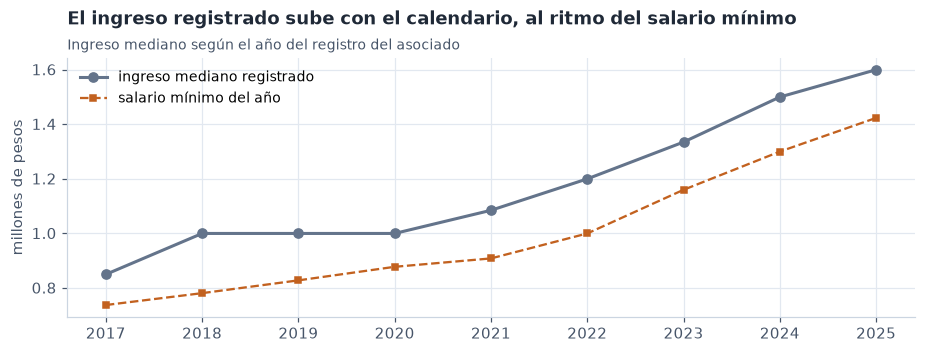

In [13]:
by_year = df.groupby("process_year")["ingresos"].median()
fig, ax = plt.subplots(figsize=(8.5, 3.3))
ax.plot(by_year.index, by_year.values, color=NEUTRAL, lw=2, marker="o", label="ingreso mediano registrado")
ax.plot(list(MIN_WAGE_BY_YEAR), list(MIN_WAGE_BY_YEAR.values()), color=CHURN, lw=1.5, ls="--", marker="s", ms=4,
        label="salario mínimo del año")
ax.set_ylabel("millones de pesos"); ax.legend(loc="upper left")
titled(ax, "El ingreso registrado sube con el calendario, al ritmo del salario mínimo",
       "Ingreso mediano según el año del registro del asociado")
plt.tight_layout(); plt.show()

**Hallazgos.**

- **La unidad de los montos son millones de pesos**: los valores más repetidos del ingreso son exactamente el salario
  mínimo de cada año (1,4235 = $1.423.500 de 2025; 1,30 de 2024; 1,16 de 2023…). Esto confirma la unidad que usa el
  notebook 01.
- **Casi uno de cada cuatro ingresos (23 %) es exactamente un salario mínimo**, y el ingreso mediano sube con el año
  del registro, por encima del salario mínimo y en paralelo con él. El ingreso está en **pesos nominales**: depende del calendario, no solo del asociado.
- **Por qué importa:** el salario mínimo de 2025 solo puede aparecer en registros de 2025, que son casi todos de
  activos. Por eso esos asociados radican mucho menos que el resto (tabla). El ingreso **lleva escondida una parte de
  la fecha** que ya decidimos excluir.

**Decisión:** el ingreso se conserva (es información real del asociado), se marca `income_is_min_wage` como columna
auxiliar y se agrega a la lista de **sospechas de fuga a medir** en la etapa 4. Recomendación al equipo: expresar el
ingreso en **número de salarios mínimos del año del registro**.

## 5. Señal: ¿qué variables separan a quien radica?

Primero la vista general (cuánto separa cada variable por sí sola) y después el detalle de las más fuertes.

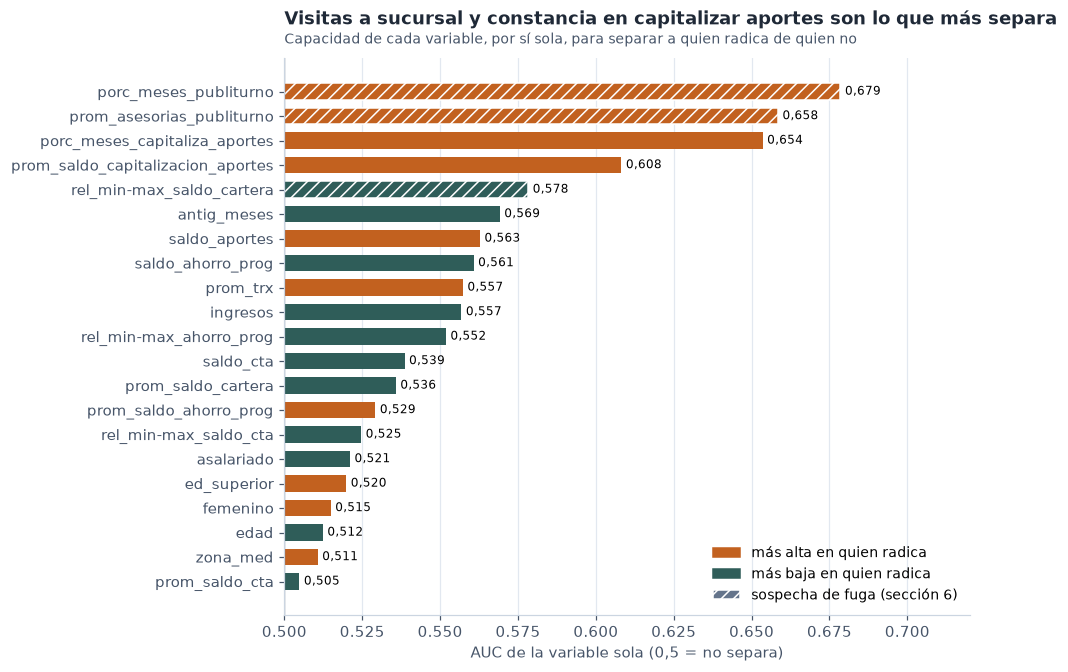

,AUC univariado
porc_meses_publiturno,"0,679"
prom_asesorias_publiturno,"0,658"
porc_meses_capitaliza_aportes,"0,654"
prom_saldo_capitalizacion_aportes,"0,608"
rel_min-max_saldo_cartera,"0,578"
antig_meses,"0,569"


In [14]:
y = df[TARGET]
auc = pd.Series({c: roc_auc_score(y, df[c].fillna(df[c].median())) for c in BASE_FEATURES})
strength = (auc - 0.5).abs() + 0.5
order = strength.sort_values()
higher_in_filers = auc[order.index] > 0.5

fig, ax = plt.subplots(figsize=(9, 6.2))
bars = ax.barh(order.index, order.values - 0.5, left=0.5,
               color=[CHURN if h else STAY for h in higher_in_filers], height=0.68)
for bar, name in zip(bars, order.index):
    if name in LEAKAGE_SUSPECTS:
        bar.set_hatch("///"); bar.set_edgecolor("white")
ax.bar_label(bars, labels=[fmt_num(v, 3) for v in order.values], padding=3, fontsize=8)
ax.axvline(0.5, color=SUBTEXT, lw=0.8)
ax.set_xlim(0.5, 0.72)
ax.set_xlabel("AUC de la variable sola (0,5 = no separa)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CHURN, label="más alta en quien radica"), Patch(color=STAY, label="más baja en quien radica"),
                   Patch(facecolor=NEUTRAL, hatch="///", edgecolor="white", label="sospecha de fuga (sección 6)")],
          loc="lower right")
titled(ax, "Visitas a sucursal y constancia en capitalizar aportes son lo que más separa",
       "Capacidad de cada variable, por sí sola, para separar a quien radica de quien no")
plt.tight_layout(); plt.show()
display(table(pd.DataFrame({"AUC univariado": strength.sort_values(ascending=False)}).head(6), decimals=3))

**Lectura (vista macro).**

- **Ninguna variable separa sola** (la mejor queda lejos de 1). El valor del modelo estará en **combinarlas**.
- Las más fuertes son de **comportamiento**: frecuencia de visitas a sucursal, asesorías y constancia en capitalizar
  aportes, todas **más altas en quien radica**. Las dos primeras son además sospechosas de fuga (sección 6).
- Las sociodemográficas (sexo, zona, educación, edad) **casi no separan**: buena noticia para la equidad, porque el
  modelo no tendría que apoyarse en ellas.
- **Parsimonia:** ocho variables tienen un AUC por debajo de 0,53. Se medirá en la etapa 4 si aportan algo
  combinadas con las demás.

Ahora el detalle: **cómo cambia la tasa de radicación** a lo largo de cada variable fuerte.

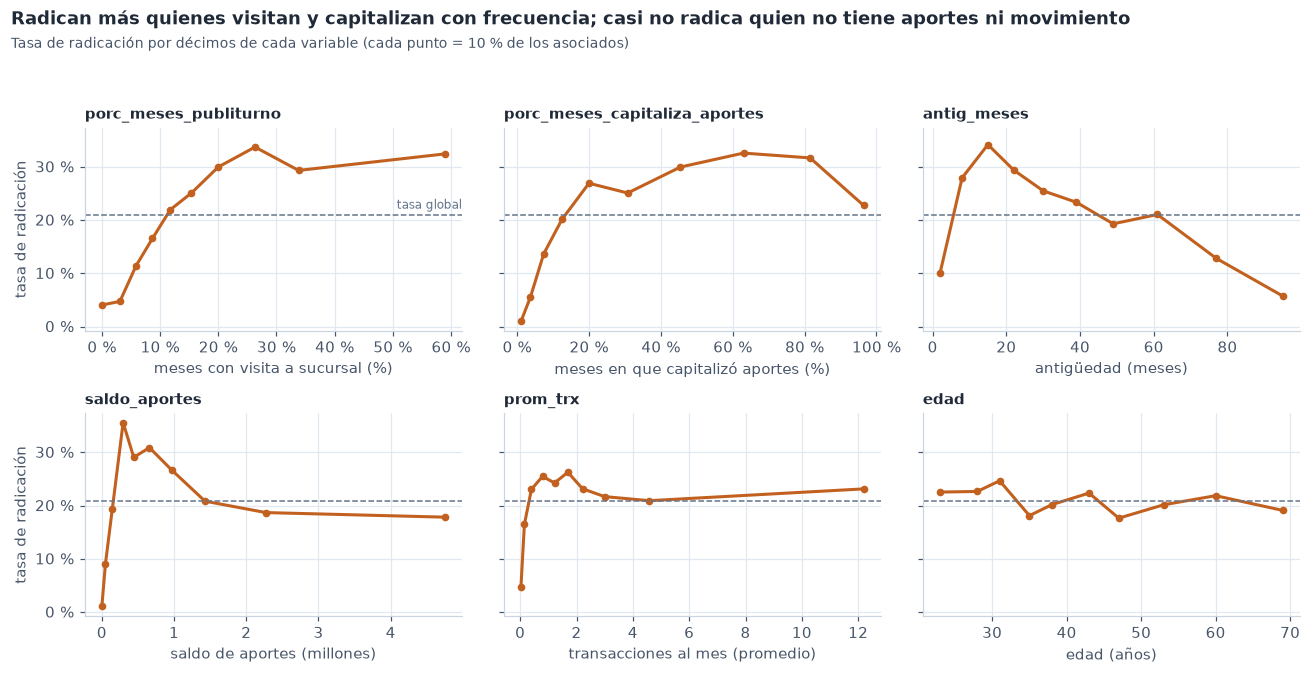

In [15]:
panels = [
    ("porc_meses_publiturno", "meses con visita a sucursal (%)", True),
    ("porc_meses_capitaliza_aportes", "meses en que capitalizó aportes (%)", True),
    ("antig_meses", "antigüedad (meses)", False),
    ("saldo_aportes", "saldo de aportes (millones)", False),
    ("prom_trx", "transacciones al mes (promedio)", False),
    ("edad", "edad (años)", False),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharey=True)
for ax, (col, label, is_pct) in zip(axes.ravel(), panels):
    r = rate_by_quantile(df[col], y, q=10)
    ax.plot(r["x_median"], r["rate"], color=CHURN, lw=2, marker="o", ms=4)
    ax.axhline(rate, color=NEUTRAL, ls="--", lw=1)
    ax.set_xlabel(label + ("" if not is_pct else ""))
    if is_pct:
        pct_axis(ax, "x")
    ax.set_title(col, fontsize=9.5, loc="left", color=TEXT)
pct_axis(axes[0, 0]); pct_axis(axes[1, 0])
axes[0, 0].set_ylabel("tasa de radicación"); axes[1, 0].set_ylabel("tasa de radicación")
axes[0, 0].text(axes[0, 0].get_xlim()[1], rate + 0.012, "tasa global", color=NEUTRAL, fontsize=8, ha="right")
fig.suptitle("Radican más quienes visitan y capitalizan con frecuencia; casi no radica quien no tiene aportes ni movimiento",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold", color=TEXT)
fig.text(0.01, 0.925, "Tasa de radicación por décimos de cada variable (cada punto = 10 % de los asociados)",
         fontsize=9, color=SUBTEXT, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.91)); plt.show()

**Lectura (detalle).**

- **Visitas a sucursal:** quien nunca visita casi no radica; la tasa sube con la frecuencia de visitas hasta superar
  el 30 %. Es la relación más fuerte, pero puede incluir la visita para radicar (sección 6).
- **Capitalización de aportes:** quien casi nunca capitaliza casi no radica; el máximo está entre el 60 % y el 80 % de
  los meses. Coincide con la lectura del equipo: hay asociados que ven los aportes como **un ahorro que se puede sacar**,
  no como vínculo.
- **Antigüedad:** sube muy rápido en el primer año y luego cae (detalle en el siguiente gráfico).
- **Saldo de aportes:** con aportes cercanos a cero casi nadie radica (no hay nada que retirar). El máximo está
  alrededor de 0,3 millones y la tasa baja por debajo del promedio por encima de 1,5 millones. El monto importa sobre
  todo para el **valor** del retiro (notebook 01).
- **Transacciones:** quien casi no transacciona casi no radica; por encima de eso el efecto es plano.
- **Edad:** sin relación clara.

**Patrón común:** el asociado "dormido" (sin aportes, sin movimiento, sin visitas) **no radica**: no tiene nada que
retirar, o sale por otra vía (sección 2). El riesgo está en el asociado **activo y transaccional**.

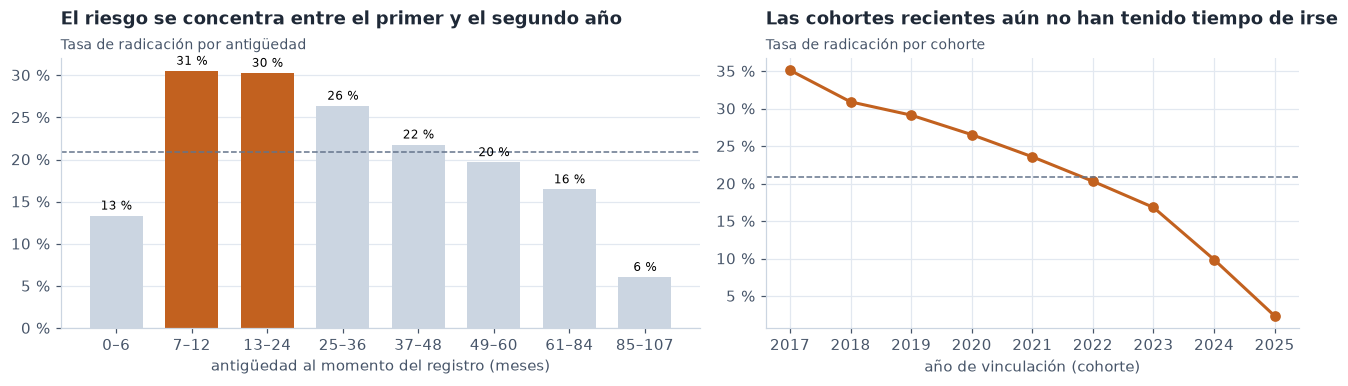

,tasa,asociados
antig_meses,,
0–6,"13,4 %",24.599
7–12,"30,5 %",17.402
13–24,"30,3 %",31.977
25–36,"26,4 %",27.091
37–48,"21,8 %",24.337
49–60,"19,7 %",19.827
61–84,"16,5 %",28.703
85–107,"6,1 %",20.137


In [16]:
tenure = pd.cut(df["antig_meses"], [-1, 6, 12, 24, 36, 48, 60, 84, 108],
                labels=["0–6", "7–12", "13–24", "25–36", "37–48", "49–60", "61–84", "85–107"])
by_tenure = df.groupby(tenure, observed=True)[TARGET].agg(["mean", "size"])
by_cohort = df.groupby(df["cohorte"].str[:4])[TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
peak = by_tenure["mean"].idxmax()
bars = ax.bar(by_tenure.index.astype(str), by_tenure["mean"],
              color=[CHURN if k in ("7–12", "13–24") else LIGHT for k in by_tenure.index], width=0.7)
ax.bar_label(bars, labels=[fmt_pct(v, 0) for v in by_tenure["mean"]], fontsize=8, padding=2)
ax.axhline(rate, color=NEUTRAL, ls="--", lw=1)
pct_axis(ax); ax.set_xlabel("antigüedad al momento del registro (meses)"); ax.grid(axis="x", visible=False)
titled(ax, "El riesgo se concentra entre el primer y el segundo año", "Tasa de radicación por antigüedad")
ax = axes[1]
ax.plot(by_cohort.index, by_cohort.values, color=CHURN, lw=2, marker="o")
ax.axhline(rate, color=NEUTRAL, ls="--", lw=1)
pct_axis(ax); ax.set_xlabel("año de vinculación (cohorte)")
titled(ax, "Las cohortes recientes aún no han tenido tiempo de irse", "Tasa de radicación por cohorte")
plt.tight_layout(); plt.show()
display(table(by_tenure.rename(columns={"mean": "tasa", "size": "asociados"}), decimals=0, pct_cols=["tasa"]))

**Lectura.**

- **El retiro es un fenómeno de los primeros años:** entre los 7 y los 24 meses de vinculación la tasa supera el 30 %,
  y después baja de forma sostenida. En los primeros seis meses es menor, porque casi nadie alcanza a irse tan pronto.
  Para la campaña es una pista clara: **el primer y el segundo año son la ventana de riesgo**.
- **Las cohortes recientes radican menos porque no han tenido tiempo**, no porque sean más fieles: el dato está
  "censurado" a la derecha. `antig_meses` le da al modelo esa exposición; se interpreta con cuidado.

### ¿Qué variables dicen casi lo mismo?

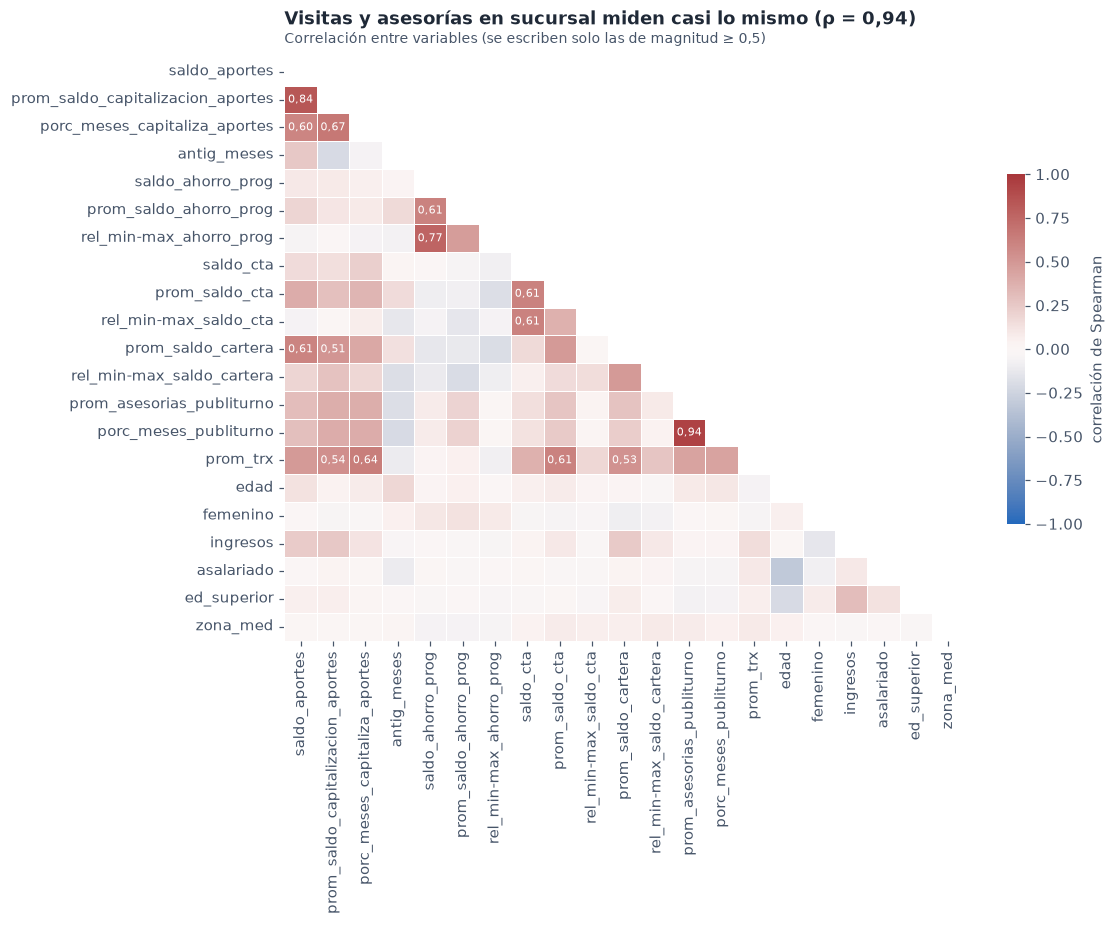

,,ρ
porc_meses_publiturno,prom_asesorias_publiturno,"0,94"
prom_saldo_capitalizacion_aportes,saldo_aportes,"0,84"
rel_min-max_ahorro_prog,saldo_ahorro_prog,"0,77"
porc_meses_capitaliza_aportes,prom_saldo_capitalizacion_aportes,"0,67"
prom_trx,porc_meses_capitaliza_aportes,"0,64"


In [17]:
corr = df[BASE_FEATURES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10.5, 8.5))
annot = corr.map(lambda v: f"{v:.2f}".replace(".", ",") if abs(v) >= 0.5 else "")
sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-1, vmax=1, center=0, annot=annot, fmt="", annot_kws={"fontsize": 7.5},
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6, "label": "correlación de Spearman"}, ax=ax)
ax.grid(False)
top_pair = corr.where(~mask).stack().abs().idxmax()
titled(ax, f"Visitas y asesorías en sucursal miden casi lo mismo (ρ = {fmt_num(corr.loc[top_pair], 2)})",
       "Correlación entre variables (se escriben solo las de magnitud ≥ 0,5)")
plt.tight_layout(); plt.show()
pairs = corr.where(~mask).stack().sort_values(key=abs, ascending=False).head(5).rename("ρ").to_frame()
display(table(pairs, decimals=2))

**Lectura.** Casi todas las correlaciones son moderadas, con tres grupos redundantes:

- `porc_meses_publiturno` y `prom_asesorias_publiturno` **son casi la misma variable**: una cuenta meses con visita y la
  otra, asesorías por mes.
- `saldo_aportes` y `prom_saldo_capitalizacion_aportes` también van muy juntas.
- Cada saldo de ahorro o cuenta con su promedio y su razón mínimo/máximo.

**Consecuencias:** en la regresión logística los coeficientes de variables redundantes se vuelven inestables, y en
SHAP su aporte se reparte entre ellas (por eso no se leen por separado). En la etapa 4 se probará conservar **una de
cada pareja**, por parsimonia.

## 6. ¿Algo que suene a fuga?

La pregunta de negocio es: *¿esta columna se conoce **antes** de que el asociado decida radicar?* La campaña contacta
**antes** de la radicación; todo lo que se mida en el mes de la radicación (o por causa de ella) es sospechoso.

In [18]:
last_month = process.max()
in_last = process == last_month
leak_dates = pd.DataFrame({
    "asociados": [int(in_last.sum()), int((~in_last).sum())],
    "tasa de radicación": [df.loc[in_last, TARGET].mean(), df.loc[~in_last, TARGET].mean()],
}, index=[f"registro en {last_month}", "registro en cualquier otro mes"])
display(table(leak_dates, decimals=0, pct_cols=["tasa de radicación"]))

window = df["porc_meses_publiturno"] * (df["antig_meses"] + 1)
window_alt = df["porc_meses_publiturno"] * df["antig_meses"]
print(f"porc_meses_publiturno × (antig_meses + 1) es un número entero en el {fmt_pct(np.isclose(window, window.round(), atol=1e-3).mean())} "
      f"de las filas (× antig_meses: {fmt_pct(np.isclose(window_alt, window_alt.round(), atol=1e-3).mean())})")

,asociados,tasa de radicación
registro en 2025-12,130.534,"0,6 %"
registro en cualquier otro mes,63.539,"62,7 %"


porc_meses_publiturno × (antig_meses + 1) es un número entero en el 96,9 % de las filas (× antig_meses: 9,4 %)


**Hallazgo 1 · Las fechas.** Si el registro es de diciembre de 2025, casi nadie radicó; si es de cualquier otro mes, la
mayoría sí lo hizo (tabla). El mes del registro es **la respuesta disfrazada**, y `cohorte` + `antig_meses` lo
reconstruye. **Decisión:** `anio_mes_proceso` y `cohorte` se eliminan en la limpieza. `antig_meses` se conserva: la
antigüedad de hoy se conoce al decidir.

**Hallazgo 2 · La ventana incluye el mes del proceso.** Los porcentajes de meses se calculan sobre *antigüedad + 1*
meses, es decir, contando el mes del registro. **Para quien radica, ese es el mes en que radicó.** Si radicó en una
sucursal, esa visita ya está dentro de `porc_meses_publiturno`.

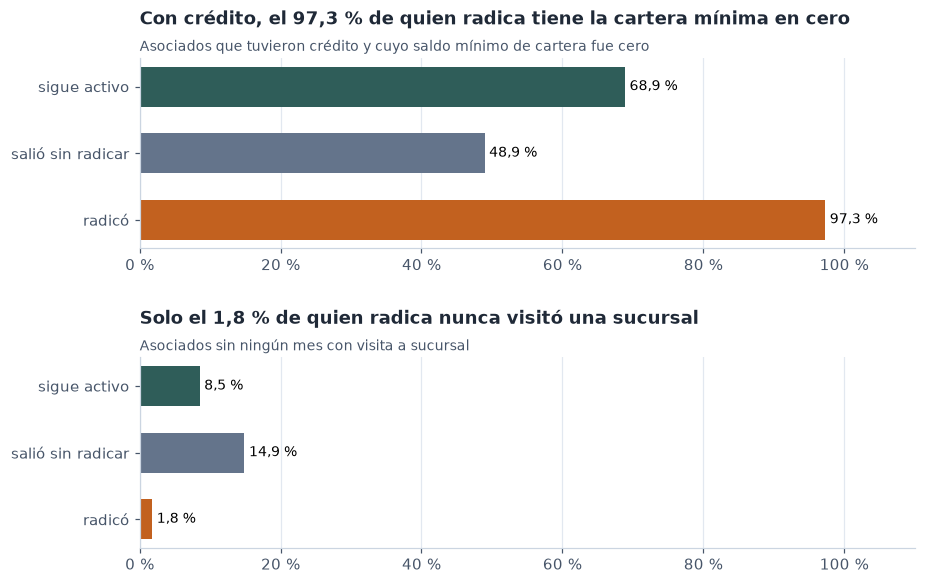

In [19]:
had_loan = df["prom_saldo_cartera"] > 0
leak = pd.DataFrame({
    "sin visitas a sucursal": df.groupby("stratum")["porc_meses_publiturno"].apply(lambda s: (s == 0).mean()),
    "con crédito: mínimo de cartera en cero": df[had_loan].groupby("stratum")["rel_min-max_saldo_cartera"].apply(lambda s: (s == 0).mean()),
}).reindex(list(labels))
leak.index = [labels[k] for k in leak.index]

fig, axes = plt.subplots(2, 1, figsize=(8.5, 5.4))
for ax, col, conclusion, subtitle in [
    (axes[0], "con crédito: mínimo de cartera en cero",
     f"Con crédito, el {fmt_pct(leak.iloc[2, 1], 1)} de quien radica tiene la cartera mínima en cero",
     "Asociados que tuvieron crédito y cuyo saldo mínimo de cartera fue cero"),
    (axes[1], "sin visitas a sucursal",
     f"Solo el {fmt_pct(leak.iloc[2, 0], 1)} de quien radica nunca visitó una sucursal",
     "Asociados sin ningún mes con visita a sucursal"),
]:
    bars = ax.barh(leak.index[::-1], leak[col][::-1], color=[CHURN, NEUTRAL, STAY], height=0.6)
    ax.bar_label(bars, labels=[fmt_pct(v, 1) for v in leak[col][::-1]], padding=3, fontsize=9)
    pct_axis(ax, "x"); ax.set_xlim(0, 1.1); ax.grid(axis="y", visible=False)
    titled(ax, conclusion, subtitle)
plt.tight_layout(h_pad=2.5); plt.show()

**Hallazgo 3 · Dos variables que pueden reflejar el trámite, no la intención.**

- **Cartera:** entre quienes tuvieron crédito, casi todos los que radican tienen el **mínimo de cartera en cero**; entre
  los activos, menos de siete de cada diez. Para retirarse hay que saldar o cruzar el crédito con los aportes: el cero
  puede ser **consecuencia** del retiro y no una señal previa.
- **Visitas:** casi nadie que radica deja de tener visitas a sucursal, frente a uno de cada doce activos. Coherente con
  la visita para radicar.

**Decisión:** no se descartan por intuición. `porc_meses_publiturno`, `prom_asesorias_publiturno` y
`rel_min-max_saldo_cartera` quedan como **sospechas de fuga** (en `config.LEAKAGE_SUSPECTS`) y en la etapa 4 el modelo se
mide **con y sin ellas**. La solución de fondo está en manos del equipo, que tiene el panel mensual: **recalcular las
variables hasta el mes anterior a la radicación** (o con unos meses de anticipación, que es lo que la campaña necesita).

## 7. Decisiones que salen del EDA

Cada fila se convierte en código con pruebas en `src/proyecto/data/cleaning.py` (notebook 03) o en una tarea de la etapa 4.

| # | Hallazgo (con cifra) | Decisión | Motivo | Dónde |
|---|---|---|---|---|
| 1 | El `Nit` es el documento del asociado; 194.073 Nit distintos en 194.073 filas | Se elimina al cargar y se reemplaza por `associate_id` | Dato personal; un identificador único no aporta señal | `load_raw` |
| 2 | Una fila = un asociado; ninguno se repite | Partición por asociado (equivale a por fila), estratificada por grupo, 80/20 | Unidad de análisis; mantener la mezcla radica / activo / salió en las dos partes | `split_by_group` |
| 3 | Registro fuera de dic-2025 → mayoría radicó; en dic-2025 → casi nadie; `cohorte + antig` = mes del registro en el 100 % | Se eliminan `anio_mes_proceso` y `cohorte` | Delatan la respuesta | `drop_time_columns` |
| 4 | Tasa de radicación 20,9 %; "siempre no" acierta 79,1 % | Métrica de negocio (beneficio neto) + PR-AUC; nunca exactitud | La exactitud premia al modelo que no encuentra a nadie | Notebook 01 |
| 5 | 23.688 asociados (12,2 %) salieron sin radicar, con perfil propio | Se conservan como 0 y se marcan en `exit_without_request` (auxiliar) | No radicaron; medir el modelo con y sin ellos en la etapa 4 | `add_time_context` |
| 6 | 39 edades imposibles (24 < 14 años, 15 > 100; 10 con 125) | Edad fuera de 14–100 → vacío; se imputa en el Pipeline | Error o centinela; no se borran filas | `mask_implausible` |
| 7 | Saldos en cero = no tiene el producto (52 % sin crédito); razones mín./máx. ambiguas en cero | Se agregan `has_loan`, `has_prog_savings`, `has_account` | Distinguir "no tiene" de "tiene poco" | `add_product_flags` |
| 8 | Ventana de cálculo incluye el mes del registro (96,9 %); con crédito, 97,3 % de quien radica tiene cartera mínima en cero | Sospechas de fuga: medir con y sin en la etapa 4; pedir al equipo recalcular a t−1 | Pueden ser consecuencia del trámite de retiro | `LEAKAGE_SUSPECTS` |
| 9 | 23 % de los ingresos = salario mínimo exacto del año de registro; ingreso mediano sube con el año | Se conserva y se marca `income_is_min_wage` (auxiliar); sospecha a medir | Pesos nominales: lleva parte de la fecha | `flag_min_wage_income` |
| 10 | Topes de origen en 5 variables; colas largas en cartera (máx. 1.333) y transacciones (máx. 531) | No se recortan; log dentro del Pipeline para modelos sensibles a escala | Ya fueron tratados; son valores reales | Etapa 4 |
| 11 | 421 capitalizaciones negativas (0,22 %); 306 filas gemelas de asociados distintos | Se conservan | Retiros parciales reales; personas distintas | — |
| 12 | Visitas y asesorías: ρ = 0,94; aportes y capitalización: ρ = 0,84 | Probar conservar una de cada pareja en la etapa 4 | Parsimonia; coeficientes y SHAP estables | Etapa 4 |

## 8. Qué queda abierto

- **Confirmar con la fuente** (Carlos y Jaqueline): qué son los 23.688 asociados que salieron sin radicar, si la ventana
  de las variables incluye el mes de radicación, y que los montos están en millones de pesos.
- **El horizonte de la predicción.** El dataset dice *si* el asociado radicó en algún momento, no *cuándo*. La campaña
  necesita "¿radicará en los próximos meses?". Con el panel mensual se puede reconstruir así (es la mejora de mayor valor
  para el proyecto).
- Las sospechas de fuga y el ingreso se **miden** en la etapa 4, con la métrica de negocio.

**Entregables:** `reports/01_eda.md` con esta tabla · `especificaciones/02-eda.md` llena.
**Siguiente:** `03_preprocesamiento.ipynb`.